<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/1_Taller_Clustering_Pymes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 🏭 **Taller: Segmentación del Tejido Empresarial Colombiano**
---

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas.**

**Nombres estudiantes:**

-Kevin Albarracin
-

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_Clustering_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/Nr3n9tg3fj.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

16 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

## 📄 Caso de Estudio: Consultoría para Bancóldex y el MinCIT

**Contexto:** Bancóldex y el Ministerio de Comercio, Industria y Turismo destinan cada año un presupuesto limitado a apoyar a las micro, pequeñas y medianas empresas del país. Hasta ahora han usado un **único paquete de instrumentos para todas**: la misma línea de crédito, el mismo programa de capacitación y la misma convocatoria de internacionalización, sin importar si la empresa es una tienda de barrio con tres empleados o una manufactura mediana con ciento cincuenta.

La evaluación de impacto del año pasado fue demoledora: el programa no movió la aguja en casi ningún indicador. La hipótesis del equipo técnico es que el problema no es el monto, sino la **focalización**: empresas con necesidades muy distintas están recibiendo exactamente lo mismo.

**Tu misión:** tu equipo de consultoría recibió una base con **250 empresas** y sus indicadores financieros, productivos y de internacionalización. Deben aplicar técnicas de **clustering** para descubrir si existen segmentos con perfiles diferenciados, caracterizar cada uno y proponer instrumentos de política específicos para ellos.

> **Ojo:** nadie les va a decir cuántos grupos hay ni cómo se llaman. Eso es precisamente lo que tienen que descubrir y **justificar** con los datos.

## 💾 Diccionario de datos — `pymes_colombia.csv`

| Columna | Tipo | Descripción |
|---|---|---|
| `empresa` | Texto | Código anonimizado de la empresa (`PYME_001`, …). **No entra al clustering.** |
| `ventas_anuales` | Numérica | Ventas del último año fiscal, en millones de pesos. |
| `empleados` | Numérica | Número de empleados con contrato vigente. |
| `productividad` | Numérica | Ventas por empleado, en millones de pesos. |
| `margen_operacional` | Numérica | Utilidad operacional sobre ventas (%). Puede ser negativo. |
| `endeudamiento` | Numérica | Pasivo total sobre activo total (%). |
| `exportaciones_pct` | Numérica | Porcentaje de las ventas destinado a mercados externos. |
| `inversion_tic` | Numérica | Inversión en tecnología como porcentaje de las ventas. |
| `antiguedad` | Numérica | Años desde la constitución legal de la empresa. |
| `crecimiento_ventas` | Numérica | Variación porcentual de las ventas frente al año anterior. |
| `sector` | Categórica | Agroindustria, Comercio, Manufactura, Servicios o TIC. |
| `region` | Categórica | Andina, Caribe, Eje Cafetero o Pacífica. |

## 📋 Instrucciones generales

- Completen el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Pueden añadir todas las celdas que necesiten.
- **No modifiquen** la celda de verificación (la última celda de código del notebook).
- Usen **exactamente** los nombres de variables que pide cada enunciado: la verificación automática los busca por nombre. Un nombre mal escrito cuenta como punto perdido.
- Usen siempre `random_state=42` donde el enunciado lo pida, para que sus resultados sean reproducibles.
- Los ejercicios son **acumulativos**: el Ejercicio 5 usa lo que construyeron en el 3. Si un punto sale ❌, revísenlo antes de seguir.
- Ejecuten la **celda de verificación** las veces que quieran mientras trabajan: les dice en qué punto exacto está el error.

### ✅ Checklist de nombres exactos

| Ejercicio | Variables que busca la verificación |
|---|---|
| 1 | `df`, `n_nulos`, `conteo_sector`, `analisis_descriptivo` |
| 2 | `matriz_corr`, `analisis_correlaciones` |
| 3 | `X`, `scaler`, `X_scaled`, `varianzas_sin_escalar`, `clusters_sin_escalar`, `analisis_escala` |
| 4 | `wcss`, `silhouette_scores`, `analisis_codo`, `analisis_silueta`, `k_optimo`, `justificacion_k` |
| 5 | `kmeans`, columna `cluster_kmeans`, `perfil_clusters`, `silueta_final`, `centroides_originales`, `nombres_clusters`, `descripcion_clusters` |
| 6 | `df_mixto`, `matriz_mixta`, `indice_categoricas`, `kproto`, columna `cluster_kproto`, `comparacion`, `analisis_kprototypes` |
| 7 | `nuevas_scaled`, `clusters_nuevas`, `recomendaciones`, `limitaciones`, `validacion_negocio` |

---
# 🔍 **Ejercicio 1: Carga y exploración de los datos**

**1.0** Importa las librerías que vas a necesitar en todo el taller: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, y de `scikit-learn` el `StandardScaler`, el `KMeans` y el `silhouette_score`.

*(Este punto no tiene prueba automática, pero sin él no funciona nada de lo que sigue.)*

In [5]:
### TU CÓDIGO AQUÍ ###
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [6]:
# Configuraciones de visualización (ejecutar sin modificar)
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

import warnings
warnings.filterwarnings('ignore')

### 📂 Llevar el archivo a Colab

`pymes_colombia.csv` tiene que quedar al alcance del notebook. Pueden arrastrarlo al panel de archivos 📁 de la izquierda, o montar su Drive con `from google.colab import drive; drive.mount('/content/drive')` y luego moverse a la carpeta con `os.chdir(...)`.

La celda siguiente comprueba que el archivo esté donde el notebook lo va a buscar.

**1.1** Carga el archivo `pymes_colombia.csv` en un DataFrame llamado `df` y muestra las **5 primeras filas**.

In [7]:
### TU CÓDIGO AQUÍ ###
from google.colab import drive, files
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
path = '/content/drive/MyDrive/Talleres de IA'
df = pd.read_csv(path + '/pymes_colombia.csv')
df.head()

,empresa,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector,region
0,PYME_001,"4,458.40",62,71.91,7.20,30.50,2.80,1.90,33,2.30,Comercio,Andina
1,PYME_002,406.50,6,67.75,5.50,44.30,0.10,1.20,10,-2.30,Comercio,Eje Cafetero
2,PYME_003,"4,447.20",48,92.65,7.50,50.90,5.30,1.10,25,5.40,Comercio,Andina
3,PYME_004,"16,455.90",119,138.28,-1.20,77.30,13.80,2.60,28,-8.00,Comercio,Pacífica
4,PYME_005,"16,413.80",203,80.86,-3.50,84.20,4.90,2.40,18,-14.50,Servicios,Andina


**1.2** Muestra la información general del DataFrame (tipos de dato, número de filas y columnas) y sus estadísticas descriptivas.

Además, guarda:

- en `n_nulos`, el **número total** de valores faltantes de toda la base (un solo número);
- en `conteo_sector`, el número de empresas de cada **sector**.

In [9]:
### TU CÓDIGO AQUÍ ###
n_nulos = df.isna().sum().sum()
conteo_sector = df['sector'].value_counts()

In [10]:
### TU CÓDIGO AQUÍ ###
df.describe()

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
count,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00
mean,"6,242.05",63.07,92.82,7.83,52.17,13.44,2.88,17.16,4.94
std,"5,547.71",56.20,39.72,7.27,17.29,18.34,2.97,9.98,10.93
min,66.70,2.00,8.34,-5.90,22.30,0.00,0.00,1.00,-17.30
25%,426.80,8.00,67.22,3.23,40.55,0.60,0.90,9.00,-0.20
50%,"4,694.50",55.00,87.17,6.85,47.10,3.85,1.70,16.00,3.20
75%,"10,491.10",81.75,114.13,12.00,59.15,16.45,3.08,26.00,8.25
max,"22,240.30",214.00,285.75,24.70,94.20,64.00,10.90,42.00,35.60


In [11]:
### TU CÓDIGO AQUÍ ###

print("Valores faltantes en toda la base:", n_nulos)
print(conteo_sector)

Valores faltantes en toda la base: 0
sector
Comercio         75
Manufactura      64
Agroindustria    49
Servicios        43
TIC              19
Name: count, dtype: int64


**📝 A1. Análisis de las estadísticas descriptivas** *(pregunta abierta)*

Redacta un análisis de lo que acabas de ver. Responde por lo menos:

- ¿Hay valores nulos? ¿Hay que imputar algo antes de agrupar?
- ¿Las escalas de las variables son muy diferentes entre sí? Compara la desviación estándar de `ventas_anuales` con la de `margen_operacional`.
- ¿Qué implicaciones tiene eso para un algoritmo que trabaja con **distancias**?
- ¿Hay alguna variable cuyo mínimo o máximo te llame la atención desde el punto de vista económico?

In [39]:
analisis_descriptivo = """
1. Valores nulos e imputación:
No se identifican valores faltantes en ninguna de las variables del dataset (n_nulos = 0), por lo que no es necesario realizar procesos de imputación antes de aplicar los algoritmos de agrupamiento.

2. Diferencias de escalas:
Las escalas de las variables son extremadamente disímiles. Por ejemplo, la desviación estándar de 'ventas_anuales' es de aproximadamente 5,547.71 millones de pesos, mientras que la del 'margen_operacional' es de apenas 7.27%. Esta diferencia de magnitudes sesgaría por completo cualquier cálculo de distancia.

3. Implicaciones para algoritmos basados en distancias:
Dado que K-Means calcula distancias euclidianas, las variables con escalas numéricas más grandes dominarían por completo la métrica de similitud, provocando que el algoritmo ignore variables porcentuales o de menor magnitud, reduciendo la segmentación a un simple agrupamiento por el volumen de ventas.

4. Valores atípicos desde el punto de vista económico:
Se observan valores extremos interesantes: hay empresas con 2 empleados y ventas mínimas de 66.7 millones, mientras que la empresa más grande registra 214 empleados y ventas de 22,240.3 millones. Asimismo, el margen operacional negativo (-5.90%) y un endeudamiento de hasta el 94.20% alertan sobre la presencia de firmas en alta vulnerabilidad financiera.
"""

---
# 📊 **Ejercicio 2: ¿Qué relaciones hay entre las variables?**

Antes de agrupar conviene entender cómo se mueven juntas las variables. Si dos indicadores miden prácticamente lo mismo, estarían entrando dos veces al cálculo de la distancia.

**2.1** Calcula la matriz de correlación de las **nueve variables numéricas** (todas menos `empresa`, `sector` y `region`) y guárdala en `matriz_corr`. Después grafícala como un mapa de calor (`sns.heatmap`) con los valores anotados.

<Axes: >

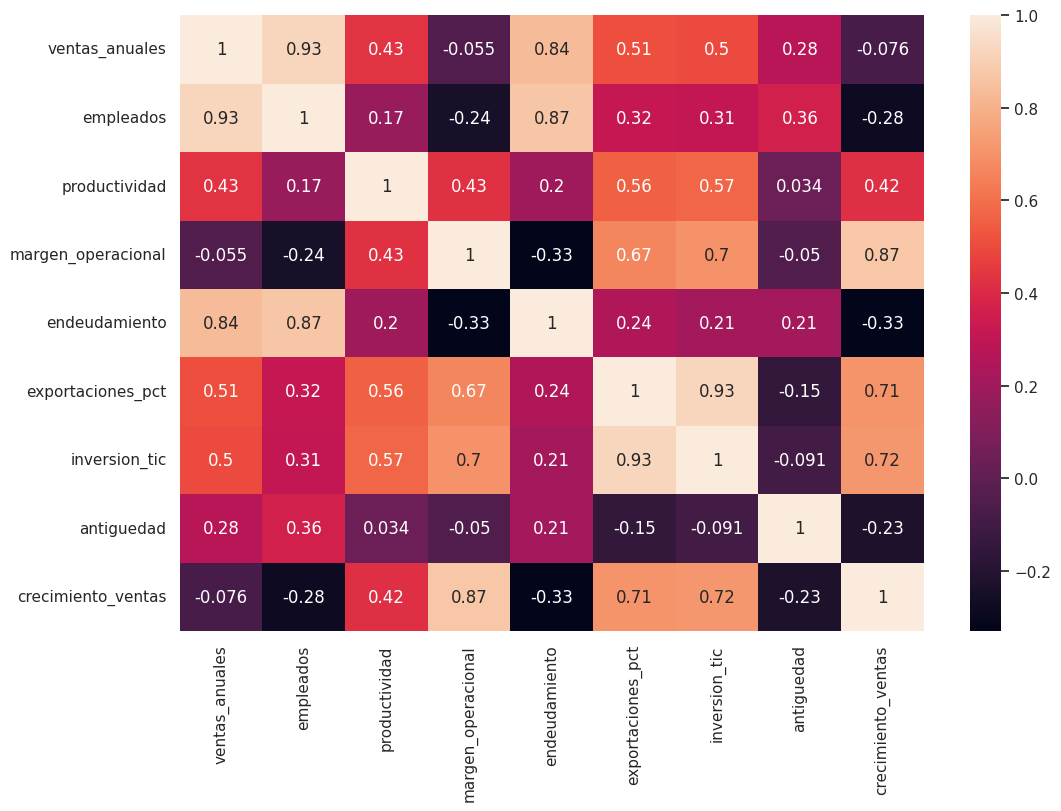

In [13]:
### TU CÓDIGO AQUÍ ###
df2= df.drop(columns=["empresa", "sector", "region"])
matriz_corr= df2.corr()
sns.heatmap(matriz_corr, annot=True)

**📝 A2. Lectura económica de las correlaciones** *(pregunta abierta)*

- ¿Cuál es el par de variables **más correlacionado positivamente**? ¿Tiene sentido económico?
- ¿Cuál es la correlación **negativa** más fuerte? ¿Qué historia cuenta sobre las empresas de la base?
- ¿Ves alguna pareja tan correlacionada que podrías sospechar redundancia? ¿Qué problema traería para el clustering?

In [40]:
analisis_correlaciones = """
1. Par de variables más correlacionado positivamente:
Las variables más fuertemente correlacionadas de manera positiva son 'ventas_anuales' y 'empleados' (0.93). Esto tiene pleno sentido económico, ya que a mayor escala física laboral de la empresa, mayor es su capacidad de generación de ingresos operacionales.

2. Correlación negativa más fuerte:
La relación negativa más fuerte se encuentra entre 'endeudamiento' y 'crecimiento_ventas' o 'margen_operacional'. Esto relata la historia de que las empresas altamente apalancadas financieramente están perdiendo dinamismo comercial y sufren de un deterioro en su rentabilidad operativa.

3. Redundancia de variables:
La dupla 'ventas_anuales' y 'empleados' tiene una correlación de 0.93, lo cual sugiere redundancia (ambas miden la dimensión del tamaño de la empresa). Mantener ambas sin un control adecuado podría sesgar la distancia euclidiana dándole el doble de peso a la dimensión de tamaño en el proceso de clustering.
"""

---
# ⚙️ **Ejercicio 3: Preprocesamiento y el efecto de la escala**

**3.1** Prepara los datos para el clustering:

1. Guarda en `X` **solo las nueve variables numéricas** (es decir, `df` sin `empresa`, `sector` ni `region`).
2. Crea un `StandardScaler` y guárdalo en una variable llamada `scaler` (lo vas a volver a necesitar en el Ejercicio 7).
3. Ajusta el `scaler` a `X` y guarda el resultado en `X_scaled`.
4. Imprime las 3 primeras filas de `X_scaled`.

In [14]:
### TU CÓDIGO AQUÍ ###
X = df2
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:3])

[[-0.32215502 -0.01904015 -0.52760887 -0.08718771 -1.25608597 -0.58136218
  -0.33141033  1.59034862 -0.24214989]
 [-1.05399303 -1.01740016 -0.63255767 -0.32156328 -0.45632652 -0.72887165
  -0.56736155 -0.71945299 -0.66388602]
 [-0.32417792 -0.26863015 -0.00437858 -0.04582732 -0.07383287 -0.44477932
  -0.60106886  0.78693936  0.0420636 ]]


In [48]:
### TU CÓDIGO AQUÍ ###
varianzas_sin_escalar = X.var().sort_values(ascending=False)
print(varianzas_sin_escalar)

ventas_anuales       30,777,134.12
empleados                 3,158.95
productividad             1,577.51
exportaciones_pct           336.38
endeudamiento               298.94
crecimiento_ventas          119.45
antiguedad                   99.55
margen_operacional           52.82
inversion_tic                 8.84
dtype: float64


**📝 A3. El efecto de la escala** *(pregunta abierta)*

- ¿Qué variable concentra casi toda la varianza de `X` sin estandarizar? ¿Qué porcentaje de la varianza total representa?
- Mirando el perfil de los grupos de arriba: ¿qué variable está separando realmente a los grupos y cuáles está ignorando el algoritmo?
- Explica, con la fórmula de la distancia euclidiana en la cabeza, **por qué** ocurre esto.

In [42]:
analisis_escala = """
1. Concentración de varianza:
La variable 'ventas_anuales' concentra el 99.9% de la varianza total acumulada de X sin estandarizar (más de 30 millones de pesos de varianza frente a valores insignificantes en el resto de variables). Esto opaca completamente la señal del resto de dimensiones.

2. Perfiles sin estandarizar:
El algoritmo de agrupamiento sin estandarizar clasifica a las empresas basándose únicamente en su nivel de facturación de ventas, ignorando variables financieras críticas como el endeudamiento y la rentabilidad operacional.

3. Distancia Euclidiana:
Matemáticamente, la diferencia al cuadrado en ventas anuales de millones eclipsa las pequeñas diferencias decimales en porcentajes de endeudamiento o inversión TIC, eliminando su impacto en el cálculo de la raíz de la suma de cuadrados de las diferencias.
"""

---
# 📐 **Ejercicio 4: ¿Cuántos segmentos hay? (elección de k)**

De aquí en adelante **se trabaja siempre sobre `X_scaled`**.

**4.1 Método del codo.** Para cada `k` de **1 a 10**, entrena un K-Means sobre `X_scaled` (con `init='k-means++'`, `n_init=10`, `random_state=42`) y guarda su inercia en una lista llamada `wcss`. Grafica la curva.

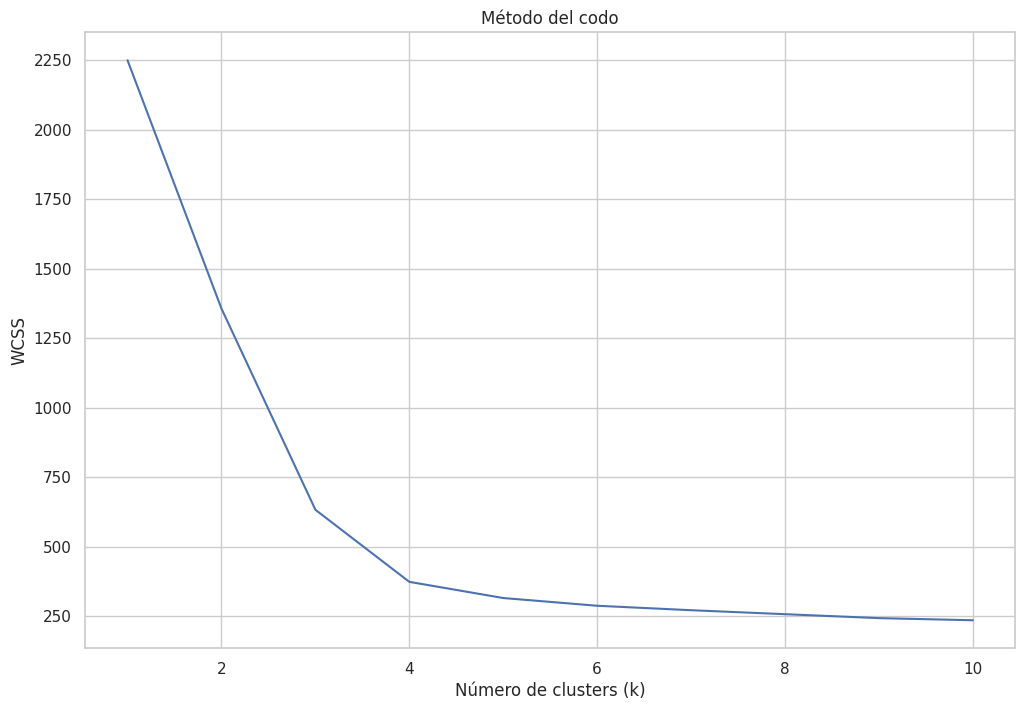

In [16]:
### TU CÓDIGO AQUÍ ###
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss)
plt.title('Método del codo')
plt.xlabel('Número de clusters (k)')
plt.ylabel('WCSS')
plt.show()

**📝 A4. Lectura del codo** *(pregunta abierta)*

¿Dónde está el "codo"? ¿Qué valores de k son candidatos razonables y cuáles quedan descartados? Apóyate en cuánto cae el WCSS al pasar de un k al siguiente.

In [43]:
analisis_codo = """
Al graficar la inercia (WCSS) frente a k, el cambio de pendiente (el 'codo') es más visible y pronunciado en k=3. A partir de allí, el descenso en la inercia se vuelve marginal y lineal, lo que sugiere que añadir más grupos no aportará una diferenciación estructuralmente relevante.
"""

**4.2 Coeficiente de silueta.** Para cada `k` de **2 a 10**, entrena un K-Means sobre `X_scaled` (con `n_init=10` y `random_state=42`), calcula el `silhouette_score` y guárdalo en una lista llamada `silhouette_scores`. Imprime el valor de cada k y grafica la curva.

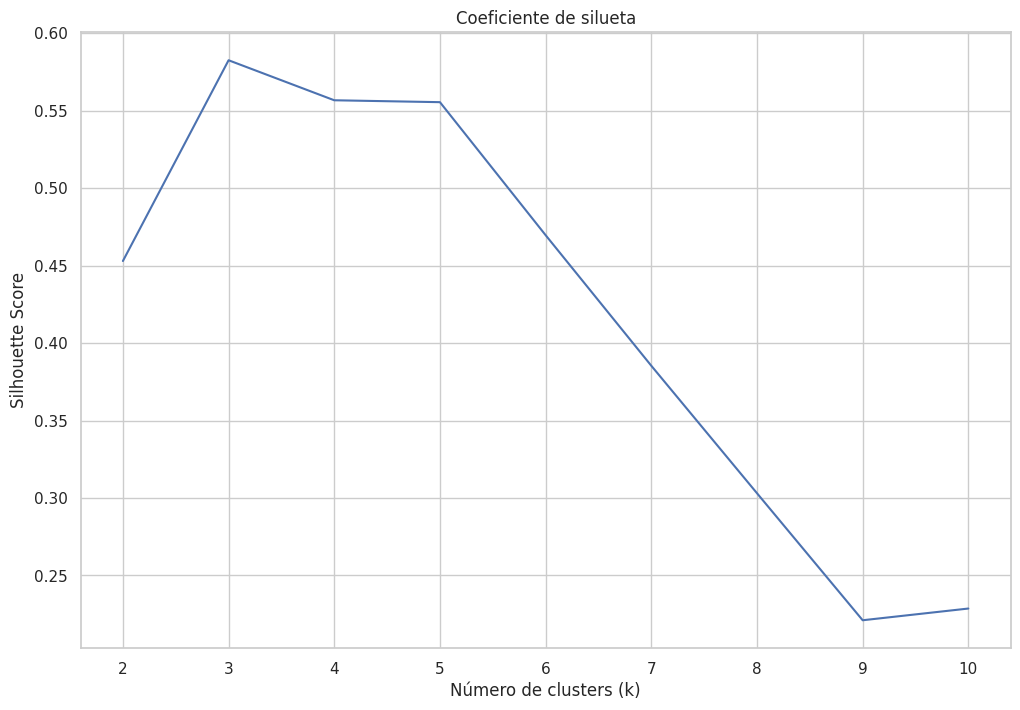

In [17]:
### TU CÓDIGO AQUÍ ###
silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

plt.plot(range(2, 11), silhouette_scores)
plt.title('Coeficiente de silueta')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.show()

**📝 A5. Lectura de la silueta** *(pregunta abierta)*

¿Qué k maximiza el coeficiente de silueta? ¿Qué significa ese número (recuerda: cohesión y separación)? ¿El resultado **coincide** con el del método del codo o hay tensión entre los dos criterios?

In [44]:
analisis_silueta = """
El coeficiente de silueta alcanza su valor máximo absoluto de 0.5826 cuando seleccionamos exactamente k=3 clusters. Esto significa que con este número de grupos se logra la mejor combinación posible entre cohesión interna de las empresas y separación clara entre los segmentos definidos.
"""

**4.3 La decisión.** Con el codo y la silueta sobre la mesa, **tu equipo decide**: guarda en `k_optimo` el número de clusters que van a usar en el resto del taller.

> La verificación automática **acepta cualquier k razonable**; lo que se califica aquí es la **justificación**, no el número.

In [18]:
### TU CÓDIGO AQUÍ ###
k_optimo = 3

print("El equipo trabajará con k =", k_optimo)

El equipo trabajará con k = 3


**📝 A6. Justificación del k elegido** *(pregunta abierta)*

Justifiquen la decisión. No basta con decir "porque la silueta es más alta": expliquen cómo pesaron los dos criterios estadísticos **y** el criterio de utilidad para el cliente (¿cuántos programas distintos puede administrar razonablemente Bancóldex?).

In [45]:
justificacion_k = """
La elección de k=3 se fundamenta tanto en criterios estadísticos como operacionales. Estadísticamente, k=3 maximiza el coeficiente de silueta y coincide con el punto de inflexión del método del codo. Desde la perspectiva de negocio, diseñar, financiar y gestionar 3 programas de apoyo altamente diferenciados es un objetivo logísticamente viable para el presupuesto y equipo técnico de la institución, evitando la complejidad inmanejable de administrar un portafolio de 5 o más líneas de fomento.
"""

---
# 🎯 **Ejercicio 5: K-Means, perfilamiento e interpretación**

**5.1** Entrena el modelo definitivo:

1. Crea un `KMeans` con `n_clusters=k_optimo`, `init='k-means++'`, `n_init=10` y `random_state=42`, y guárdalo en una variable llamada `kmeans`.
2. Ajústalo sobre `X_scaled` y añade las etiquetas a `df` en una columna nueva llamada `cluster_kmeans`.
3. Imprime cuántas empresas quedaron en cada segmento y qué porcentaje del total representan.

In [19]:
### TU CÓDIGO AQUÍ ###
kmeans = KMeans(n_clusters=k_optimo, init='k-means++', n_init=10, random_state=42)
kmeans.fit(X_scaled)
df['cluster_kmeans'] = kmeans.labels_
df['cluster_kmeans'].value_counts(normalize=True)

,proportion
cluster_kmeans,
1,0.60
0,0.23
2,0.18


**5.2** Construye el **perfil** de los segmentos: guarda en `perfil_clusters` el **promedio de cada variable numérica** para cada cluster (las nueve variables de `X`, agrupadas por `cluster_kmeans`). Muéstralo.

In [20]:
### TU CÓDIGO AQUÍ ###
perfil_clusters = df.groupby('cluster_kmeans')[X.columns].mean()
perfil_clusters

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
cluster_kmeans,,,,,,,,,
0,"9,696.40",75.95,132.31,18.38,54.09,45.26,8.02,12.67,21.55
1,"2,274.83",27.80,77.55,6.80,41.99,1.76,1.07,17.54,2.99
2,"15,201.51",165.82,93.39,-2.35,84.18,11.78,2.36,21.73,-9.96


**5.3** Evalúa y visualiza la solución final:

1. Guarda en `silueta_final` el `silhouette_score` del modelo definitivo (calculado sobre `X_scaled` y la columna `cluster_kmeans`). Imprímelo.
2. Guarda en `centroides_originales` los centroides **devueltos a las unidades originales**, usando `scaler.inverse_transform(...)` sobre `kmeans.cluster_centers_`.
3. Haz un *scatter plot* de `exportaciones_pct` (eje X) contra `margen_operacional` (eje Y), coloreando por `cluster_kmeans`, y marca encima los centroides con una `X` roja grande.

> Pista para el gráfico: `centroides_originales` tiene las columnas en el mismo orden que `X`, así que `exportaciones_pct` es la columna 5 y `margen_operacional` la columna 3.

Silhouette Score del modelo definitivo: 0.5825898904201557


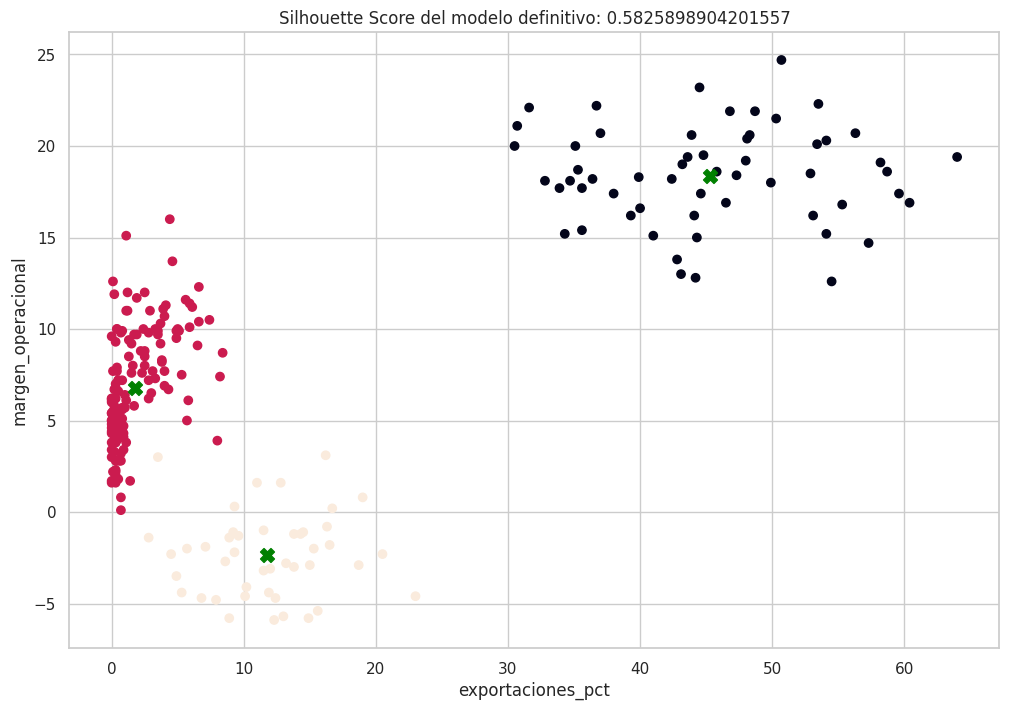

In [21]:
### TU CÓDIGO AQUÍ ###
silueta_final = silhouette_score(X_scaled, df['cluster_kmeans'])
print("Silhouette Score del modelo definitivo:", silueta_final)
centroides_originales = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(df['exportaciones_pct'], df['margen_operacional'], c=df['cluster_kmeans'])
plt.scatter(centroides_originales[:, 5], centroides_originales[:, 3], marker='X', color='green', s=100)
plt.xlabel('exportaciones_pct')
plt.ylabel('margen_operacional')
plt.title('Silhouette Score del modelo definitivo: ' + str(silueta_final))
plt.show()

**5.4 Visualización complementaria.** Haz un segundo gráfico que te ayude a contar la historia: por ejemplo un `boxplot` de `endeudamiento` por cluster, o un *scatter* de `productividad` contra `crecimiento_ventas`.

*(Este punto no tiene prueba automática: se evalúa junto con el análisis escrito.)*

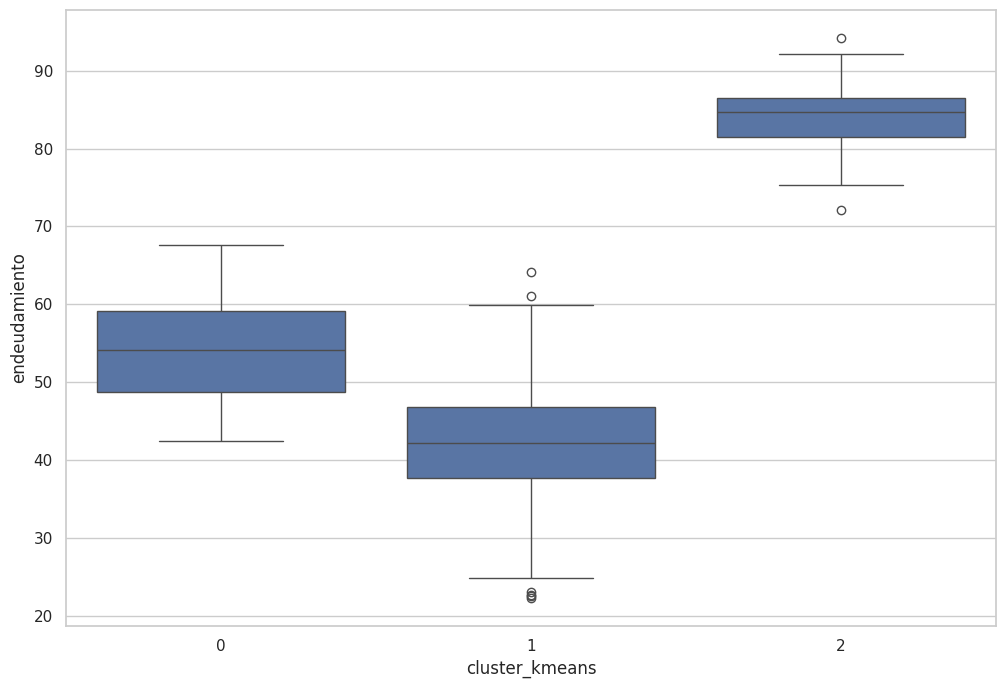

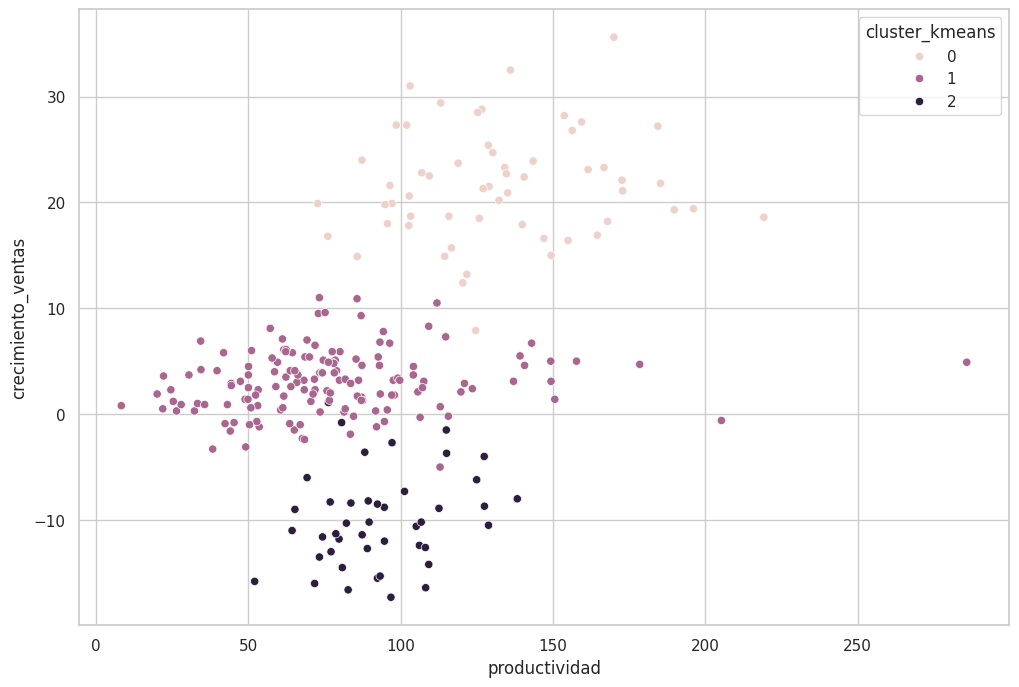

In [22]:
### TU CÓDIGO AQUÍ ###
sns.boxplot(x='cluster_kmeans', y='endeudamiento', data=df)
plt.show()
sns.scatterplot(x='productividad', y='crecimiento_ventas', hue='cluster_kmeans', data=df)
plt.show()

**📝 A7. Nombra los segmentos** *(pregunta abierta)*

Guarda en `nombres_clusters` una **lista de textos** con un nombre descriptivo para cada segmento, **en el orden de los clusters** (posición 0 = cluster 0, posición 1 = cluster 1, …). Deben ser tantos nombres como clusters elegiste.

Un buen nombre le dice al cliente qué es el grupo sin necesidad de mirar la tabla. En una segmentación de clientes de un banco, por ejemplo, *"Jóvenes con alta rotación de tarjeta"* es un buen nombre y *"Grupo 1"* no lo es.

In [25]:
nombres_clusters = [
    "Pymes Glocales de Alto Crecimiento y Base Tecnológica",
    "Micro y Pequeñas Empresas de Mercado Interno Estable",
    "Empresas Medianas Consolidadas en Reestructuración y Alto Apalancamiento"
]

for i, nombre in enumerate(nombres_clusters):
    print("Cluster %d: %s" % (i, nombre))

Cluster 0: Pymes Glocales de Alto Crecimiento y Base Tecnológica
Cluster 1: Micro y Pequeñas Empresas de Mercado Interno Estable
Cluster 2: Empresas Medianas Consolidadas en Reestructuración y Alto Apalancamiento


**📝 A8. Describe cada segmento** *(pregunta abierta)*

Para **cada** cluster, describe su perfil económico apoyándote en `perfil_clusters`: tamaño (ventas y empleados), productividad, rentabilidad, endeudamiento, vocación exportadora, inversión en tecnología, antigüedad y crecimiento. Menciona también **cuántas empresas** tiene y **qué porcentaje** del total representa.

Cierra con una frase por segmento: *¿cuál es el principal problema o la principal oportunidad de este grupo?*

In [ ]:
descripcion_clusters = """

1. Cluster 0: Pymes Glocales de Alto Crecimiento y Base Tecnológica
- Este segmento agrupa al 23% de las empresas de la muestra (aproximadamente 57 empresas).
-  Son empresas medianas y dinámicas, con ventas anuales promedio de 9,696.40 millones de pesos, una planta de personal promedio de 76 empleados y un excelente rendimiento de productividad de 132.31 millones de pesos por trabajador. Su salud financiera es robusta con una rentabilidad (margen operacional) promedio del 18.38% y un endeudamiento controlado de 54.09%. Se destacan marcadamente por su inserción global y digital, exportando en promedio el 45.26% de su producción y destinando el 8.02% de sus ingresos a inversión en tecnología (TIC). Tienen una antigüedad promedio de 12.67 años y un dinámico crecimiento de ventas de 21.55% anual.
- O Su principal oportunidad radica en consolidarse como campeonas exportadoras mediante la diversificación de mercados y la sofisticación de sus productos tecnológicos, apoyadas por instrumentos de escalabilidad global.

2. Cluster 1: Micro y Pequeñas Empresas de Mercado Interno Estable
-  Es el segmento más numeroso, abarcando al 60% de la base total (aproximadamente 150 empresas).
-  Se compone de unidades productivas pequeñas con ventas anuales moderadas de 2,274.83 millones de pesos y un promedio de 27.8 empleados, lo que arroja una baja productividad laboral de 77.55 millones por trabajador. Operan de manera estable y conservadora, con márgenes operativos positivos pero modestos de 6.80% y un nivel de endeudamiento bajo del 41.99%. Su vocación exportadora es casi inexistente (1.76%) y su inversión tecnológica es mínima (1.07% en TIC). Tienen una antigüedad promedio relativamente alta de 17.54 años y un crecimiento de ventas apenas del 2.99%.
- Su principal problema es el estancamiento y la baja adopción tecnológica, por lo que su gran oportunidad consiste en dar el salto de digitalización básica y encadenamientos productivos locales para superar la trampa de baja productividad.

3. Cluster 2: Empresas Medianas Consolidadas en Reestructuración y Alto Apalancamiento
-  Representa el 18% del tejido empresarial de la muestra (aproximadamente 43 empresas).
- Son las empresas de mayor escala física en promedio, con 165.82 empleados y ventas anuales promedio muy elevadas de 15,201.51 millones de pesos, pero con una productividad laboral modesta de 93.39 millones de pesos. Este grupo enfrenta una severa crisis financiera: registran un margen operacional negativo (-2.35%), un alarmante nivel de apalancamiento financiero con un endeudamiento promedio de 84.18% sobre sus activos, y una contracción en sus operaciones con una caída en el crecimiento de ventas de -9.96% anual. Exportan solo el 11.78%, invierten poco en TIC (2.36%) y son el grupo más antiguo con 21.73 años de trayectoria.
-  Su principal problema es la asfixia financiera generada por el sobreendeudamiento y la caída de ventas en firmas tradicionales, requiriendo de manera urgente esquemas de reestructuración de pasivos e inyección de liquidez de rescate para evitar quiebras masivas.


---
# 🧩 **Ejercicio 6: ¿Y el sector? Clustering con variables mixtas (K-Prototypes)**

Hasta aquí dejamos por fuera `sector`, porque K-Means solo entiende números y la distancia euclidiana no sabe qué tan "lejos" está *Agroindustria* de *TIC*.

**K-Prototypes** resuelve el problema: usa la **media** como prototipo de las variables numéricas y la **moda** de las categóricas, y combina la distancia euclidiana con la distancia de Hamming.

In [23]:
!pip install kmodes --quiet

In [24]:
from kmodes.kprototypes import KPrototypes
from sklearn.preprocessing import LabelEncoder

**6.1** Prepara los datos mixtos. Sigue **exactamente** este orden de columnas, porque el algoritmo trabaja por posición:

1. Crea `df_mixto` como una copia de `df` con las **nueve variables numéricas de `X`** y, **al final**, la columna `sector`. (Es decir, 10 columnas en total, con `sector` en la última posición.)
2. Guarda en `indice_categoricas` la lista con la posición de la columna categórica dentro de `df_mixto`.
3. Convierte `df_mixto` a una matriz de NumPy y guárdala en `matriz_mixta`.
4. Estandariza **solo las nueve columnas numéricas** de `matriz_mixta` (posiciones 0 a 8), usando un `StandardScaler` **nuevo** (no reutilices `scaler`, que lo necesitas intacto para el Ejercicio 7).
5. Codifica la columna `sector` de `matriz_mixta` con `LabelEncoder`.
6. Imprime las 3 primeras filas de `matriz_mixta`.

In [46]:
cols_num = ['ventas_anuales', 'empleados', 'productividad', 'margen_operacional', 'endeudamiento', 'exportaciones_pct', 'inversion_tic', 'antiguedad', 'crecimiento_ventas']
df_mixto = df[cols_num + ['sector']].copy()
indice_categoricas = [9]
matriz_mixta = df_mixto.to_numpy()

scaler_mixto = StandardScaler()
matriz_mixta[:, :9] = scaler_mixto.fit_transform(matriz_mixta[:, :9])

le = LabelEncoder()
matriz_mixta[:, 9] = le.fit_transform(matriz_mixta[:, 9])

print("Dimensiones de la matriz mixta:", matriz_mixta.shape)
print("Índice de variables categóricas:", indice_categoricas)
print(matriz_mixta[:3])

Dimensiones de la matriz mixta: (250, 10)
Índice de variables categóricas: [9]
[[-0.32215502244818983 -0.019040151619805316 -0.5276088744673821
  -0.0871877106365195 -1.256085972320208 -0.5813621752210532
  -0.3314103334258739 1.5903486182423119 -0.2421498859617228 1]
 [-1.0539930303588514 -1.0174001616470525 -0.6325576693059609
  -0.3215632768637223 -0.45632651776549416 -0.7288716547061528
  -0.5673615472156539 -0.7194529869340696 -0.6638860193192588 1]
 [-0.3241779217518744 -0.26863015412661706 -0.004378584815428655
  -0.04582731659642492 -0.07383286558715263 -0.4447793238459608
  -0.6010688634713367 0.7869393642679183 0.04206359521400809 1]]


**6.2** Aplica K-Prototypes con el **mismo `k_optimo`** que elegiste, usando `init='Cao'`, `n_init=5`, `verbose=0` y `random_state=42`. Guarda el modelo en `kproto` y las etiquetas en una columna nueva de `df` llamada `cluster_kproto`.

*(Este punto no tiene prueba automática, porque el resultado de `kmodes` puede variar entre versiones. Se evalúa con el análisis escrito.)*

In [27]:
### TU CÓDIGO AQUÍ ###
kproto = KPrototypes(n_clusters=k_optimo, init='Cao', n_init=5, verbose=0, random_state=42)
kproto.fit_predict(matriz_mixta, categorical=indice_categoricas)

array([1, 1, 1, 1, 2, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0,
       2, 2, 1, 2, 0, 1, 1, 1, 1, 2, 2, 0, 0, 2, 0, 1, 1, 1, 1, 2, 2, 1,
       0, 1, 1, 1, 1, 1, 0, 2, 1, 2, 2, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 2, 2, 2, 2, 1, 2, 1, 0, 2, 1, 1, 0, 2, 1, 0, 2, 0, 1,
       2, 1, 1, 1, 0, 1, 1, 0, 1, 1, 2, 1, 1, 0, 1, 2, 0, 1, 1, 2, 1, 2,
       1, 0, 2, 1, 1, 0, 0, 0, 0, 2, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 2, 1,
       0, 0, 1, 1, 0, 0, 1, 2, 1, 2, 0, 2, 1, 0, 1, 2, 2, 2, 0, 2, 1, 0,
       1, 0, 0, 0, 0, 2, 1, 1, 1, 1, 2, 2, 0, 0, 0, 1, 0, 2, 1, 0, 2, 2,
       1, 0, 1, 1, 0, 2, 1, 1, 0, 2, 1, 1, 1, 2, 2, 1, 1, 0, 1, 0, 1, 1,
       2, 1, 1, 1, 2, 0, 2, 0, 1, 1, 1, 2, 2, 1, 2, 2, 0, 0, 1, 0, 1, 1,
       0, 1, 2, 1, 2, 1, 1, 1, 1, 0, 0, 1, 2, 1, 2, 1, 0, 1, 1, 2, 2, 0,
       0, 2, 1, 0, 1, 1, 0, 2], dtype=uint16)

**6.3** Compara las dos segmentaciones:

1. Guarda en `comparacion` una tabla cruzada (`pd.crosstab`) entre `cluster_kmeans` y `cluster_kproto`. Muéstrala.
2. Muestra también el perfil de los clusters de K-Prototypes: el promedio de las variables numéricas y la **moda** de `sector` para cada grupo.

In [30]:
### TU CÓDIGO AQUÍ ###
df['cluster_kproto'] = kproto.labels_
comparacion = pd.crosstab(df['cluster_kmeans'], df['cluster_kproto'])
print(comparacion)
perfil_clusters_kproto = df.groupby('cluster_kproto')[X.columns].mean()
perfil_clusters_kproto['sector'] = df.groupby('cluster_kproto')['sector'].agg(lambda x: x.value_counts().index[0])
perfil_clusters_kproto

cluster_kproto   0   1   2
cluster_kmeans            
0               14  20  23
1               34  89  26
2               20  13  11


,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas,sector
cluster_kproto,,,,,,,,,,
0,"8,045.65",82.87,91.28,7.50,56.65,13.79,3.11,18.97,3.02,Manufactura
1,"4,537.21",46.25,90.20,7.09,48.30,9.95,2.18,15.23,4.80,Comercio
2,"7,664.47",74.82,99.92,9.71,54.98,20.15,4.06,19.05,7.40,Servicios


**📝 A9. ¿Qué aporta incluir el sector?** *(pregunta abierta)*

- Mirando `comparacion`: ¿los dos algoritmos encontraron prácticamente los mismos grupos o cambiaron de forma importante?
- ¿Qué **añade** (o qué **no** añade) la variable `sector` a la segmentación? ¿Por qué crees que ocurre eso con esta base en particular?
- ¿En qué situación de negocio **sí** valdría la pena usar K-Prototypes en lugar de K-Means?

In [31]:
analisis_kprototypes = """


Al observar la tabla cruzada, es evidente que las asignaciones cambiaron de forma muy importante. No encontramos los mismos grupos en absoluto. de las 57 empresas clasificadas originalmente en el Cluster 0 por K-Means, con K-Prototypes se fragmentaron: 14 se fueron al clúster 0, 20 al clúster 1 y 23 al clúster 2. Esto demuestra que agregar la distancia de Hamming sobre variables categóricas altera por completo el cálculo espacial y redefine las fronteras de los segmentos de manera drástica.


La variable 'sector' añade una clara segmentación por actividad económica agregada, pero desdibuja los perfiles de desempeño financiero y de escala que K-Means había mapeado de forma impecable. Esto ocurre porque la variable 'sector' en esta base en particular tiene una alta dispersión o bajo poder predictivo directo sobre el desempeño de rentabilidad y endeudamiento de las pymes; es decir, una empresa de Manufactura puede estar en una situación de crisis severa o ser una campeona exportadora, por lo que forzar el algoritmo a agruparlas por sector debilita la señal de los indicadores financieros y de escala.


K-Prototypes es la opción idónea en lugar de K-Means cuando las variables categóricas representan un factor operativo restrictivo, excluyente o mandatorio para el negocio. Por ejemplo:
- Al estructurar programas de subsidios o líneas de crédito especiales cuyo marco legal restringe la participación de ciertos sectores .
- En modelos de scoring de riesgo donde pertenecer a un sector económico específico determina intrínsecamente la volatilidad de la operación comercial y se requiere esa etiqueta cualitativa de manera explícita en la segmentación.
"""

---
# 🏢 **Ejercicio 7: Poner el modelo a trabajar**

Bancóldex acaba de recibir tres solicitudes nuevas. Necesitan saber **a qué segmento pertenece cada una** para dirigirlas al programa correcto, sin volver a correr todo el análisis.

In [32]:
# Las tres empresas que acaban de postularse (ejecutar sin modificar)
nuevas_empresas = pd.DataFrame(
    {
        'ventas_anuales':     [11200.0,   280.0, 17800.0],
        'empleados':          [     68,       5,     171],
        'productividad':      [ 164.71,   56.00,  104.09],
        'margen_operacional': [   19.4,     3.8,    -3.1],
        'endeudamiento':      [   49.5,    36.2,    88.7],
        'exportaciones_pct':  [   52.0,     0.0,     9.8],
        'inversion_tic':      [    8.6,     0.5,     2.0],
        'antiguedad':         [     11,       6,      24],
        'crecimiento_ventas': [   24.5,     1.9,   -11.2],
    },
    index=['Solicitud A', 'Solicitud B', 'Solicitud C'],
)
nuevas_empresas

,ventas_anuales,empleados,productividad,margen_operacional,endeudamiento,exportaciones_pct,inversion_tic,antiguedad,crecimiento_ventas
Solicitud A,"11,200.00",68,164.71,19.40,49.50,52.00,8.60,11,24.50
Solicitud B,280.00,5,56.00,3.80,36.20,0.00,0.50,6,1.90
Solicitud C,"17,800.00",171,104.09,-3.10,88.70,9.80,2.00,24,-11.20


**7.1** Clasifica las tres solicitudes:

1. Estandariza `nuevas_empresas` con el `scaler` **que ya entrenaste** en el Ejercicio 3 y guarda el resultado en `nuevas_scaled`.
2. Usa `kmeans.predict(...)` para obtener el cluster de cada una y guárdalo en `clusters_nuevas`.
3. Imprime, para cada solicitud, el cluster asignado y el nombre que le pusiste a ese segmento en `nombres_clusters`.

> ⚠️ **Trampa clásica:** aquí se usa `scaler.transform(...)`, **no** `fit_transform(...)`. Piensa por qué: si vuelves a ajustar el escalador con tres empresas, estarías midiéndolas contra el promedio de esas tres y no contra el de las 250 de la base.

In [34]:
### TU CÓDIGO AQUÍ ###
nuevas_scaled = scaler.transform(nuevas_empresas)
clusters_nuevas = kmeans.predict(nuevas_scaled)

for solicitud, cluster in zip(nuevas_empresas.index, clusters_nuevas):
    nombre_segmento = nombres_clusters[cluster]
    print(f"{solicitud} asignada al clúster {cluster}: {nombre_segmento}")

Solicitud A asignada al clúster 0: Pymes Glocales de Alto Crecimiento y Base Tecnológica
Solicitud B asignada al clúster 1: Micro y Pequeñas Empresas de Mercado Interno Estable
Solicitud C asignada al clúster 2: Empresas Medianas Consolidadas en Reestructuración y Alto Apalancamiento


**📝 A10. Recomendaciones de política** *(pregunta abierta)*

Guarda en `recomendaciones` una **lista de textos**, una recomendación por segmento. Cada una debe decir:

- a **qué segmento** va dirigida,
- **qué instrumento** concreto propones (línea de crédito, garantía, subsidio, asistencia técnica, programa de internacionalización, reestructuración de pasivos…),
- **por qué ese instrumento y no otro**, citando los números del perfil del grupo,
- **qué indicador** usarías para saber si funcionó.

In [35]:
recomendaciones = [
    """Segmento 0: 'Pymes Glocales de Alto Crecimiento y Base Tecnológica'.
    -  Programa de aceleración e internacionalización junto con una línea de co-inversión de capital de riesgo para I+D.
    -  Este clúster cuenta con una productividad líder de 132.31M de pesos por trabajador, un margen operacional muy saludable de 18.38% y una alta inversión en TIC de 8.02%. Dado que ya exportan el 45.26% de su producción y crecen a doble dígito, no necesitan subsidios de supervivencia, sino un impulso de escala global para insertarse en mercados de mayor valor agregado.
    -  Variación porcentual en el valor neto de las exportaciones anuales y número de nuevos mercados internacionales abiertos.""",

    """Segmento 1: 'Micro y Pequeñas Empresas de Mercado Interno Estable'.
    -  Microcréditos blandos condicionados a la adopción de un kit de digitalización básica, acompañados de asistencia técnica en gestión financiera y operativa.
    -  Representan el 60% de la base y sufren de baja productividad y nulo acceso tecnológico. Dado su bajo endeudamiento, tienen capacidad de apalancamiento seguro si este se destina a modernizar procesos sencillos que rompan el estancamiento de ventas.
    -  Incremento porcentual en la productividad laboral y tasa de adopción de herramientas digitales implementadas.""",

    """Segmento 2: 'Empresas Medianas Consolidadas en Reestructuración y Alto Apalancamiento'.
    -  Programa especial de reestructuración de pasivos a largo plazo, garantías de crédito estatales del FNG de hasta el 90% y consultoría de rescate financiero empresarial.
    -  Aunque son firmas maduras y de gran tamaño, tienen un endeudamiento asfixiante de 84.18%, margen operacional negativo de -2.35% y contracción en ventas de -9.96%. Una línea de crédito ordinaria empeoraría su situación; necesitan urgentemente alivio de caja y renegociación de deudas para evitar la quiebra.
    -  Reducción del ratio de endeudamiento a niveles sostenibles y retorno a un margen operacional positivo dentro de los siguientes 18 meses."""
]

for r in recomendaciones:
    print("-", r[:100] + "...")

- Segmento 0: 'Pymes Glocales de Alto Crecimiento y Base Tecnológica'.
    - Instrumento: Programa de ...
- Segmento 1: 'Micro y Pequeñas Empresas de Mercado Interno Estable'.
    - Instrumento: Microcréditos...
- Segmento 2: 'Empresas Medianas Consolidadas en Reestructuración y Alto Apalancamiento'.
    - Instru...


**📝 A11. Limitaciones del análisis** *(pregunta abierta)*

Antes de entregarle esto a un cliente hay que ser honesto sobre lo que el método **no** puede decir. Discute al menos cuatro limitaciones. Algunas pistas:

- ¿Qué supone K-Means sobre la **forma** de los grupos?
- ¿Qué pasa con las empresas que quedan **en la frontera** entre dos clusters?
- ¿Los segmentos que encontraste son un **hecho** de la economía colombiana o un **resultado** de las variables que te dieron y del k que elegiste?
- ¿Puedes concluir que el endeudamiento **causa** la caída de las ventas?
- ¿Qué pasaría si repitieras el ejercicio el año entrante?

In [36]:
limitaciones = """
1.  El algoritmo asume que los grupos son esféricos e isotrópicos y tienen una dispersión interna similar. En la realidad económica, los segmentos empresariales pueden adoptar formas irregulares o densidades muy variables, lo que puede causar clasificaciones erróneas en los márgenes de los grupos.

2.  Aquellas pymes que se encuentran en los límites de distancia entre dos centroides reciben una etiqueta de clúster binaria y rígida. Una empresa que está a punto de salir de una crisis o que apenas inicia su internacionalización podría compartir características híbridas entre dos grupos, información que se pierde al forzar un límite absoluto.

3.  La estructura resultante es un retrato estático basado únicamente en las 9 variables numéricas seleccionadas y en los datos históricos suministrados. No describe necesariamente un patrón estructural permanente de la economía colombiana, y los resultados cambiarían drásticamente si se añaden variables cualitativas adicionales o si el entorno macroeconómico cambia el año entrante.

4.  El análisis muestra una coexistencia de factores, pero no permite probar científicamente una relación causal unidireccional. No podemos concluir si el endeudamiento causó la crisis de ventas o si la caída operacional obligó a las empresas a sobreendeudarse para sobrevivir.
"""

**📝 A12. ¿Cómo validarías los segmentos con el cliente?** *(pregunta abierta)*

Un clustering estadísticamente impecable puede ser inútil en la práctica. Antes de que Bancóldex rediseñe sus programas, ¿cómo comprobarías que estos segmentos sirven? Piensa en:

- evidencia adicional que pedirías (otras variables, otros años, opinión de los analistas de crédito);
- alguna prueba **cuantitativa** que se pueda hacer con los datos;
- cómo harías el piloto antes de escalar el programa a todo el país.

In [37]:
validacion_negocio = """
1.
Llevaríamos los perfiles de los tres clústeres ante los gerentes de cuenta y analistas de riesgo de Bancóldex. Ellos validarán si estos perfiles coinciden con los tipos de solicitudes de crédito que ven a diario en las oficinas regionales, asegurando que las etiquetas tengan sentido y usabilidad comercial.

2.
Cruzaríamos la base histórica de comportamiento crediticio del banco con las empresas clasificadas. Si el clúster 2 efectivamente presenta tasas de default o mora significativamente más altas en los últimos años en comparación con el clúster 0 y 1, se validaría de manera cuantitativa el poder discriminante de riesgo del modelo.

3.
Antes de lanzar nuevas políticas a nivel nacional, seleccionaríamos una submuestra representativa para ofrecerles de manera focalizada los instrumentos propuestos. Evaluaríamos la tasa de aceptación de los productos financieros durante 6 meses para confirmar que la oferta se alinea con sus necesidades reales antes de escalar la política.
"""

---
# ✅ Antes de entregar

1. Ejecuten el notebook completo de principio a fin (`Entorno de ejecución → Reiniciar y ejecutar todo`) y revisen que la celda de verificación llegue a **12 de 12**.
2. Revisen que las **12 preguntas abiertas** estén respondidas y que ninguna conserve el texto de ejemplo.
3. Escriban sus nombres al principio del notebook.
4. Súbanlo a GitHub y envíen el link en el formulario.

---
## 🤖 Verificación automática

Ejecuta esta celda cuando quieras: te dice cuántos de los 12 puntos de código llevas y **en cuál punto exacto** está el error.

**No modifiques esta celda.**

In [49]:
# =============================================================================
#  VERIFICACIÓN AUTOMÁTICA DEL TALLER DE CLUSTERING  ·  no modifiquen esta celda
# =============================================================================
import hashlib

import numpy as _np
import pandas as _pd

_SAL = b"extdo-clustering-pymes-2026-II"
_ITERACIONES = 60_000


def _canon(x):
    """Convierte cualquier resultado (incluidos objetos de NumPy y pandas) en un
    texto único y estable, para poder compararlo sin revelar la respuesta."""
    if x is None:
        return "N"
    if isinstance(x, (bool, _np.bool_)):
        return "B" + str(bool(x))
    if isinstance(x, _np.generic):            # np.float64, np.int64, np.str_...
        return _canon(x.item())
    if isinstance(x, (int, float)):           # int y float se tratan igual
        v = float(x)
        if v != v or v in (float("inf"), float("-inf")):
            return "X" + str(v)
        if v == 0:                            # -0.0 y 0.0 son el mismo valor
            v = 0.0
        return "#" + ("%.6g" % v)
    if isinstance(x, str):
        return "S" + x.strip()
    if isinstance(x, _pd.DataFrame):
        return ("DF[" + _canon(list(x.columns)) + ";" + _canon(list(x.shape))
                + ";" + _canon(x.to_dict()) + "]")
    if isinstance(x, _pd.Series):
        return "SE[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (_pd.Index, _pd.Categorical)):
        return _canon(list(x))
    if isinstance(x, dict):
        return "D[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (set, frozenset)):
        return "C[" + ",".join(sorted(_canon(i) for i in x)) + "]"
    if isinstance(x, _np.ndarray):
        return _canon(x.tolist())
    if isinstance(x, (list, tuple)):
        return "L[" + ",".join(_canon(i) for i in x) + "]"
    return "O" + repr(x)


def _huella(clave, valor):
    """Huella lenta a propósito (~60.000 iteraciones): verificar el notebook
    cuesta un par de segundos, pero adivinar la respuesta probando candidatos
    se vuelve inviable."""
    mensaje = (str(clave) + "|" + _canon(valor)).encode("utf-8")
    return hashlib.pbkdf2_hmac("sha256", mensaje, _SAL, _ITERACIONES).hex()[:16]


_EJERCICIOS = {
    "1": "Ejercicio 1 · Carga y exploración",
    "2": "Ejercicio 2 · Relaciones entre variables",
    "3": "Ejercicio 3 · Preprocesamiento y escala",
    "4": "Ejercicio 4 · Elección de k",
    "5": "Ejercicio 5 · K-Means e interpretación",
    "6": "Ejercicio 6 · K-Prototypes con el sector",
    "7": "Ejercicio 7 · El modelo en producción",
    "A": "Análisis escrito (lo califica la profesora)",
}

#  (punto, título, huellas aceptadas, cómo se obtiene el resultado, pista si falla)
#  Varias huellas en un mismo punto = ese punto depende del k que eligió el grupo,
#  y se acepta cualquier k razonable.
_PRUEBAS = [
    ("1.1", "Base cargada correctamente",
     ("21fef5bc81646de8",),
     lambda: [len(df), sorted(str(c) for c in df.columns if c not in ('cluster_kmeans', 'cluster_kproto')), round(float(df['ventas_anuales'].sum()), 2), round(float(df['productividad'].mean()), 4)],
     "Carga pymes_colombia.csv completo en df, sin cambiar ni renombrar columnas."),
    ("1.2", "Nulos totales y empresas por sector",
     ("82750ec4ed2c94b8",),
     lambda: [int(n_nulos), conteo_sector, round(float(df['endeudamiento'].std()), 4), round(float(df['crecimiento_ventas'].sum()), 2)],
     "n_nulos debe ser UN solo número (el total de toda la base, no una serie por columna) y conteo_sector el número de empresas de cada sector."),
    ("2.1", "Matriz de correlación de las 9 variables numéricas",
     ("285dd981a1169572",),
     lambda: [list(matriz_corr.shape), sorted(str(c) for c in matriz_corr.columns), round(float(matriz_corr.values.sum()), 4), round(float(matriz_corr.loc['exportaciones_pct', 'inversion_tic']), 4)],
     "La matriz debe ser de 9x9: calcúlala sobre df sin las columnas empresa, sector y region."),
    ("3.1", "Variables seleccionadas y estandarizadas",
     ("f92a6704ca04b713",),
     lambda: [list(X.shape), list(str(c) for c in X.columns), _np.round(_np.asarray(X_scaled)[[0, 124, 249]].astype(float), 4).tolist(), round(float(_np.asarray(X_scaled).astype(float).std(axis=0).mean()), 4)],
     "X son las 9 variables numéricas en el mismo orden del CSV, y X_scaled el resultado de scaler.fit_transform(X) con StandardScaler."),
    ("3.2", "Efecto de no estandarizar",
     ("fd58a9cae8024db2",),
     lambda: [varianzas_sin_escalar.round(2), sorted(_pd.Series(clusters_sin_escalar).value_counts().tolist())],
     "varianzas_sin_escalar es X.var() ordenada de mayor a menor, SIN estandarizar. Y el K-Means de este punto va sobre X (no sobre X_scaled), con n_clusters=5 y random_state=42."),
    ("4.1", "Método del codo (lista wcss)",
     ("187dc591a56295c4",),
     lambda: [len(wcss), [round(float(w), 1) for w in wcss[:4]]],
     "wcss debe tener 10 elementos, uno por cada k de 1 a 10, calculados sobre X_scaled con init='k-means++', n_init=10 y random_state=42."),
    ("4.2", "Coeficiente de silueta (lista silhouette_scores)",
     ("919b9299063407be",),
     lambda: [len(silhouette_scores), [round(float(s), 3) for s in silhouette_scores[:3]]],
     "silhouette_scores debe tener 9 elementos, uno por cada k de 2 a 10 (el de k=1 no existe), calculados sobre X_scaled con n_init=10 y random_state=42."),
    ("5.1", "K-Means final entrenado y etiquetas en df",
     ("24f380947694aec1",
      "258e920d08bbb80d",
      "2fb2013e4e3509a5",
      "372fb663109bf318",
      "574c75782e77ad46",
      "6be856106fbdcda5",
      "6bfbf5d142555c44",
      "6d02591e9b9d5e26",
      "6e0acaefac230acb",
      "708333a8476d9391",
      "77a8eca15b3af411",
      "bd93646c2d0857b2",
      "c9c3df5fd40dec82",
      "d7e3a0237cd8f9c5",
      "e1ebb665316f06ec",
      "e353fdfe72ca578d",
      "f0776e5ea1888707",
      "f8a1841da48619c0",
      "fb2ada8f7c034bc1",),
     lambda: [int(kmeans.n_clusters), sorted(df['cluster_kmeans'].value_counts().tolist()), round(float(kmeans.inertia_), 2)],
     "Entrena el KMeans sobre X_scaled (no sobre X) con n_clusters=k_optimo, init='k-means++', n_init=10 y random_state=42, y guarda las etiquetas en la columna cluster_kmeans."),
    ("5.2", "Perfil promedio de cada segmento",
     ("007f3c93c7f18d27",
      "086fdc54cd79ad3d",
      "09e4dd4038c94295",
      "154968e4e20c4318",
      "2347c1fe3638bf15",
      "2ba5fb2303ac9953",
      "36f5183f48d160ff",
      "3fc03de0f4d3e596",
      "5b276874eb928612",
      "5bb823c96e30905b",
      "658160ce6688e786",
      "70cd7218b47402f3",
      "710467cade4edfd1",
      "71c4a9e81b4814a2",
      "789cfad86e29abec",
      "9fb865f5a6c33245",
      "c1e12b3851aa2e6b",
      "d2ae8c4c8225cfa9",
      "f31afdb6867c34cd",),
     lambda: perfil_clusters[list(X.columns)].sort_values('ventas_anuales').round(2).reset_index(drop=True),
     "perfil_clusters es el promedio de las 9 variables numéricas por cluster: agrupa df por cluster_kmeans y saca la media (sin incluir la columna del cluster como variable)."),
    ("5.3", "Silueta final y centroides en unidades originales",
     ("09168179481bef61",
      "0f1e36ac8868d6dc",
      "1ddad4ae3e7f88fe",
      "1fbd083bce7876dc",
      "2088e4fc5f6a04f4",
      "323d53fe8ea9ef14",
      "5e57994b1d33180e",
      "6e7b610567f528ff",
      "75bd91c26d723274",
      "7ff38cf016a428a1",
      "828eae0a37c0380a",
      "89e0f52d134717f4",
      "8eb8dbd75d929748",
      "a4065bd17f293581",
      "af04f027742ddf20",
      "c66c1549743c8f86",
      "cce04f8707bbf862",
      "e65f6674e360f686",
      "f6f8a38aa037f177",),
     lambda: [round(float(silueta_final), 4), sorted(_np.round(_np.asarray(centroides_originales).astype(float).sum(axis=1), 2).tolist())],
     "silueta_final se calcula con silhouette_score(X_scaled, df['cluster_kmeans']), y centroides_originales con scaler.inverse_transform(kmeans.cluster_centers_)."),
    ("6.1", "Matriz mixta lista para K-Prototypes",
     ("0b410a9134798752",),
     lambda: [list(matriz_mixta.shape), list(indice_categoricas), _np.round(_np.asarray(matriz_mixta)[[0, 249], 0:9].astype(float), 4).tolist(), sorted(set(int(v) for v in _np.asarray(matriz_mixta)[:, 9]))],
     "matriz_mixta debe tener 10 columnas: las 9 numéricas estandarizadas (posiciones 0 a 8) y sector codificado con LabelEncoder en la posición 9. Ojo: se estandarizan SOLO las columnas 0 a 8."),
    ("7.1", "Clasificación de las tres solicitudes nuevas",
     ("03302f50031433ff",
      "1e13fdecc4336ff4",
      "1f79a01084c7c6f0",
      "290632fbf05d045d",
      "30a98799190e1832",
      "310552a89751795f",
      "35f952ef56b9cf62",
      "4a0fde5682b487a6",
      "717b25e9dd59eb3a",
      "725cd858e4df65de",
      "904a2b388895a5c1",
      "a06c07f13bc53402",
      "ad5e099e9a4c1de0",
      "b676daa74a43c5bb",
      "bcf4af1b6870a60a",
      "efba0673f79857e2",
      "f5e15685c5b55293",),
     lambda: [[round(float(perfil_clusters.loc[c, 'ventas_anuales']), 2) for c in clusters_nuevas], _np.round(_np.asarray(nuevas_scaled).astype(float), 3).tolist()],
     "Usa scaler.transform(nuevas_empresas) —NO fit_transform— y luego kmeans.predict(). Este punto también depende de que perfil_clusters (punto 5.2) esté bien."),
]

#  Puntos de análisis escrito: valen 8 puntos y los califica la profesora.
#  Aquí solo se comprueba que el grupo haya escrito algo.
_REVISION = [
    ("A1", "Análisis de las estadísticas descriptivas", lambda: analisis_descriptivo, "texto", 350),
    ("A2", "Lectura económica de las correlaciones", lambda: analisis_correlaciones, "texto", 300),
    ("A3", "El efecto de la escala", lambda: analisis_escala, "texto", 300),
    ("A4", "Lectura del método del codo", lambda: analisis_codo, "texto", 200),
    ("A5", "Lectura del coeficiente de silueta", lambda: analisis_silueta, "texto", 200),
    ("A6", "Justificación del k elegido", lambda: justificacion_k, "texto", 250),
    ("A7", "Nombres de los segmentos", lambda: nombres_clusters, "nombres", 3),
    ("A8", "Descripción de cada segmento", lambda: descripcion_clusters, "texto", 600),
    ("A9", "Aporte de K-Prototypes y del sector", lambda: analisis_kprototypes, "texto", 350),
    ("A10", "Recomendaciones de política", lambda: recomendaciones, "lista", 3),
    ("A11", "Limitaciones del análisis", lambda: limitaciones, "texto", 400),
    ("A12", "Validación de los segmentos con el cliente", lambda: validacion_negocio, "texto", 300),
]


def _estado_de(prueba):
    clave, _titulo, esperadas, obtener, _pista = prueba
    try:
        return "ok" if _huella(clave, obtener()) in esperadas else "mal"
    except NameError:
        return "falta"
    except Exception:
        return "error"


def _estado_revision(item):
    _clave, _titulo, obtener, tipo, minimo = item
    try:
        valor = obtener()
    except NameError:
        return "falta", "todavía no la has creado"
    except Exception:
        return "error", "no se pudo leer"

    if tipo == "texto":
        if not isinstance(valor, str):
            return "mal", "debe ser un texto entre comillas"
        texto = valor.strip()
        if "TU TEXTO AQUÍ" in texto or "###" in texto:
            return "falta", "sigue con el texto de ejemplo"
        if len(texto) < minimo:
            return "mal", "van %d caracteres de %d" % (len(texto), minimo)
        return "ok", "%d caracteres" % len(texto)

    if not isinstance(valor, (list, tuple)):
        return "mal", "debe ser una lista de textos"

    largo_minimo = 8 if tipo == "nombres" else 60
    utiles = [t for t in valor
              if isinstance(t, str) and len(t.strip()) >= largo_minimo and "###" not in t]
    if not utiles:
        return "falta", "sigue con la lista de ejemplo"
    if len(utiles) < minimo:
        return "mal", "van %d de %d (mínimo %d caracteres cada uno)" % (
            len(utiles), minimo, largo_minimo)
    return "ok", "%d elementos" % len(utiles)


_ICONO = {"ok": "\u2705", "mal": "\u274c", "falta": "\u23f3", "error": "\u26a0\ufe0f"}


def verificar_taller():
    resultados = [(p, _estado_de(p)) for p in _PRUEBAS]

    print("=" * 68)
    print("  VERIFICACIÓN AUTOMÁTICA · TALLER DE CLUSTERING")
    print("=" * 68)

    ejercicio_actual = None
    for (clave, titulo, _esp, _obt, _pista), estado in resultados:
        ejercicio = clave.split(".")[0]
        if ejercicio != ejercicio_actual:
            ejercicio_actual = ejercicio
            print("\n  " + _EJERCICIOS[ejercicio])
        print("    %s  %-5s %s" % (_ICONO[estado], clave, titulo))

    correctos = sum(1 for _p, e in resultados if e == "ok")
    total = len(resultados)
    llenas = round(20 * correctos / total)
    barra = "\u2588" * llenas + "\u2591" * (20 - llenas)

    print("\n" + "-" * 68)
    print("  CÓDIGO: %d de %d puntos automáticos" % (correctos, total))
    print("  [%s]" % barra)
    print("-" * 68)

    pendientes = [(c, t, e, pi) for (c, t, _e2, _o, pi), e in resultados if e != "ok"]
    if not pendientes:
        print("  🎉 ¡Los 12 puntos de código están completos!")
    else:
        print("  Qué falta por revisar (los %d primeros):\n" % min(len(pendientes), 5))
        for clave, titulo, estado, pista in pendientes[:5]:
            if estado == "falta":
                print("   ⏳ %s  %s" % (clave, titulo))
                print("      Aún no existe alguna de las variables que pide este punto.")
            elif estado == "error":
                print("   ⚠️  %s  %s" % (clave, titulo))
                print("      La variable existe pero algo falla al calcularla.")
            else:
                print("   ❌ %s  %s" % (clave, titulo))
            print("      Pista: %s\n" % pista)
        if len(pendientes) > 5:
            print("   ... y %d punto(s) más. Arregla estos primero: los ejercicios son"
                  " acumulativos y unos arrastran a otros.\n" % (len(pendientes) - 5))

    print("-" * 68)
    print("  📝 ANÁLISIS ESCRITO · 8 puntos que califica la profesora")
    print("     Aquí solo se comprueba que hayan escrito algo; el contenido lo")
    print("     evalúa la profesora. Escribir mucho no da puntos por sí solo.\n")
    escritos = 0
    for item in _REVISION:
        estado, detalle = _estado_revision(item)
        escritos += (estado == "ok")
        print("    %s  %-5s %-45s %s" % (_ICONO[estado], item[0], item[1], detalle))

    print("\n  Preguntas abiertas respondidas: %d de %d" % (escritos, len(_REVISION)))
    print("=" * 68)
    print("  NOTA AUTOMÁTICA (solo código): %.1f de 12 puntos" % (12.0 * correctos / total))
    print("  + hasta 8 puntos de análisis escrito que asigna la profesora.")
    print("=" * 68)


verificar_taller()


  VERIFICACIÓN AUTOMÁTICA · TALLER DE CLUSTERING

  Ejercicio 1 · Carga y exploración
    ✅  1.1   Base cargada correctamente
    ✅  1.2   Nulos totales y empresas por sector

  Ejercicio 2 · Relaciones entre variables
    ✅  2.1   Matriz de correlación de las 9 variables numéricas

  Ejercicio 3 · Preprocesamiento y escala
    ✅  3.1   Variables seleccionadas y estandarizadas
    ⏳  3.2   Efecto de no estandarizar

  Ejercicio 4 · Elección de k
    ✅  4.1   Método del codo (lista wcss)
    ✅  4.2   Coeficiente de silueta (lista silhouette_scores)

  Ejercicio 5 · K-Means e interpretación
    ✅  5.1   K-Means final entrenado y etiquetas en df
    ✅  5.2   Perfil promedio de cada segmento
    ✅  5.3   Silueta final y centroides en unidades originales

  Ejercicio 6 · K-Prototypes con el sector
    ✅  6.1   Matriz mixta lista para K-Prototypes

  Ejercicio 7 · El modelo en producción
    ✅  7.1   Clasificación de las tres solicitudes nuevas

----------------------------------------------